# mpstab vs qibojit vs PauliPropagation.jl: who wins where

Three simulators of the same circuits:

- **mpstab**: the HSMPO surrogate, a stabilizer tableau for the Clifford gates
  and an MPS for the magic ones, applied as dressed Pauli rotations;
- **qibojit** (qibo's numba backend): exact statevector, or exact density
  matrix with noise;
- **PauliPropagation.jl**: the observable propagated backwards as a sum of
  Pauli strings, truncated at `min_abs_coeff`.

None of them wins everywhere, and this notebook shows both sides.

| regime | best choice | why |
|---|---|---|
| few qubits (≲ 20) | qibojit | exact and simple; its cost doubles with every qubit |
| shallow circuits, local observable | Pauli propagation | the observable's light cone holds a handful of Pauli strings |
| noisy circuits, local observable | Pauli propagation | noise damps Pauli strings, so truncation gets easier; mpstab samples faults and pays variance |
| deep circuits, many qubits | **mpstab** | Pauli propagation's term count explodes with depth; the MPS bond dimension grows far more slowly |
| observables with many terms | **mpstab** | one MPS serves every term; Pauli propagation pays per term |
| many observables, same circuit | **mpstab** | the surrogate is built once; Pauli propagation re-propagates for each |

Every error is measured against an exact value: qibojit where it fits, and
otherwise mpstab with no bond-dimension cap and no SVD cutoff, which involves
no approximation at all and is checked against qibojit below.

**Launch** from the repository root:

```bash
uv run --with juliacall --with qibojit --with pandas --with jupyterlab \
    jupyter lab examples/notebooks/benchmarks/frameworks.ipynb
```

The first run downloads Julia and PauliPropagation.jl (a few minutes).

**Timings** are wall clock for one evaluation. mpstab: everything (Clifford
split, dressing, MPS evolution). qibojit: circuit execution and contraction,
after a numba warm-up, running multithreaded. PauliPropagation: the
propagation alone, compiled first; runs that could blow up go to a separate
process that is abandoned after `TIMEOUT` seconds.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from qibo import set_backend

import frameworks as fw

set_backend("numpy")  # mpstab's own qibo calls; qibojit is used as an object
pd.set_option("display.precision", 4)

TIMEOUT = 60  # seconds per PauliPropagation run in the mpstab regime
MARKERS = {"mpstab": "s", "qibojit": "D", "PauliPropagation": "o"}


def exact_mpstab(circuit, observable):
    """mpstab with no bond cap and no SVD cutoff: no approximation at all."""
    return fw.run_mpstab(circuit, observable, max_bond=None, svd_cutoff=0.0)


def pp_isolated(circuit, observable, threshold, steps):
    """PauliPropagation in a child process, compiled on one Floquet step first."""
    return fw.run_pp_isolated(circuit, [], observable, timeout=TIMEOUT,
                              warmup_gates=len(circuit.queue) // steps,
                              min_abs_coeff=threshold)


def plot_methods(df, x, title, xlabel=None):
    """Error and time against `x`, one line per method; timeouts as x marks."""
    greens = iter(["#7cc9a6", "#1baf7a", "#0c5c3c", "#008300"])
    blues = iter(["#2a78d6", "#6250d6", "#1f4f8f"])
    fig, (ax_error, ax_time) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
    for method, d in df.groupby("method", sort=False):
        family = method.split()[0]
        color = fw.COLORS["qibojit"] if family == "qibojit" else next(
            blues if family == "mpstab" else greens)
        style = dict(color=color, marker=MARKERS[family], markersize=6, linewidth=2, label=method)
        done = d.dropna(subset=["time"])
        ax_time.plot(done[x], done["time"], **style)
        errors = done.dropna(subset=["error"])
        if len(errors):
            ax_error.plot(errors[x], errors["error"].clip(lower=1e-16), **style)
        timed_out = d[d["time"].isna()]
        if len(timed_out):
            ax_time.plot(timed_out[x], [TIMEOUT] * len(timed_out), "x", color=color,
                         markersize=9, mew=2)
    if df["time"].isna().any():
        ax_time.axhline(TIMEOUT, color="0.6", linestyle=":", linewidth=1)
        ax_time.annotate(f"timeout ({TIMEOUT} s)", (df[x].min(), TIMEOUT), xytext=(0, 4),
                         textcoords="offset points", fontsize=8, color="0.4")
    ax_error.set(yscale="log", xlabel=xlabel or x, ylabel="|value - exact|", title="error")
    ax_time.set(yscale="log", xlabel=xlabel or x, ylabel="wall time [s]", title="time")
    for ax in (ax_error, ax_time):
        ax.grid(alpha=0.3)
        ax.legend(frameon=False, fontsize=9)
    fig.suptitle(title)
    return fig

[Qibo 0.3.6|INFO|2026-11-17 10:41:33]: Using numpy backend on /CPU:0


In [2]:
jit = fw.qibojit_backend()
pp = fw.PauliPropagation()  # installs + warms up Julia on first use

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


## 1. Sanity check: all three agree

A small kicked Ising circuit, with and without noise. Noiseless, the three
agree to machine precision; with noise, PauliPropagation still matches
qibojit and mpstab lands within a few `stderr` (its multi-fault part is
sampled).

In [3]:
n, depth = 8, 3
circuit = fw.kicked_ising(n, depth)
for events in ([], fw.noise_events(circuit, p=0.005, crosstalk=0.02)):
    rows = fw.compare(circuit, events, fw.local_z(n), qibojit=jit, pauli_propagation=pp,
                      pp_options=dict(min_abs_coeff=1e-10),
                      mpstab_options=dict(n_samples=1000, seed=0))
    print("noisy" if events else "noiseless")
    display(pd.DataFrame(rows).set_index("framework")[["value", "error", "time"]])

noiseless


,value,error,time
framework,,,
mpstab,0.3266,3.3307e-16,0.0039
qibojit,0.3266,0.0000e+00,0.0076
PauliPropagation,0.3266,8.8818e-16,0.0004


noisy


,value,error,time
framework,,,
mpstab,0.2404,2.6561e-04,0.4459
qibojit,0.2401,0.0000e+00,0.1779
PauliPropagation,0.2401,4.9314e-12,0.0010


### The exact reference beyond qibojit

mpstab with no bond cap and no SVD cutoff makes no approximation. Against
qibojit it agrees to $10^{-14}$; beyond qibojit's reach it is the reference
for the rest of the notebook.

In [4]:
for n in (12, 16, 20, 24):
    circuit, observable = fw.kicked_ising(n, 6), fw.local_z(n, (n // 2,))
    reference = fw.run_qibojit(jit, circuit, [], observable)
    ours = exact_mpstab(circuit, observable)
    print(f"n={n}: |mpstab - qibojit| = {abs(ours['value'] - reference['value']):.1e}   "
          f"mpstab {ours['time']:.3f} s, qibojit {reference['time']:.3f} s")

n=12: |mpstab - qibojit| = 9.1e-15   mpstab 0.009 s, qibojit 0.023 s
n=16: |mpstab - qibojit| = 1.4e-14   mpstab 0.011 s, qibojit 0.036 s


/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: divide by zero encountered in matmul
  return func(*args, **kwargs)
/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: overflow encountered in matmul
  return func(*args, **kwargs)
/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: invalid value encountered in matmul
  return func(*args, **kwargs)


n=20: |mpstab - qibojit| = 1.4e-14   mpstab 0.014 s, qibojit 0.149 s


n=24: |mpstab - qibojit| = 1.7e-14   mpstab 0.016 s, qibojit 3.231 s


## 2. Where Pauli propagation wins: shallow circuits, local observables

A kicked Ising circuit of depth 2–3 and the two-site observable
$Z_0 Z_{n-1}$: its light cone holds a few dozen Pauli strings at any width, so
Pauli propagation does almost no work.

n=8: mpstab 0.00311s  qibojit 0.0072s  PauliPropagation 0.000319s


n=12: mpstab 0.00433s  qibojit 0.011s  PauliPropagation 0.000527s


n=16: mpstab 0.006s  qibojit 0.0181s  PauliPropagation 0.000464s


n=20: mpstab 0.00681s  qibojit 0.109s  PauliPropagation 0.000548s


n=24: mpstab 0.00836s  qibojit 2.2s  PauliPropagation 0.000555s


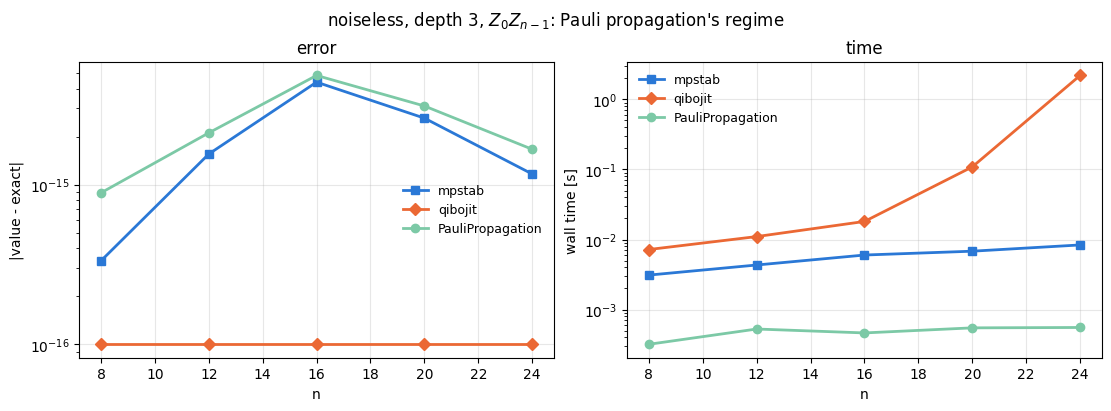

In [5]:
SIZES = [8, 12, 16, 20, 24]
shallow = fw.sweep(((n, fw.kicked_ising(n, 3), [], fw.local_z(n)) for n in SIZES),
                   label="n", qibojit=jit, pauli_propagation=pp,
                   pp_options=dict(min_abs_coeff=1e-6))
shallow["method"] = shallow["framework"]
plot_methods(shallow, "n", "noiseless, depth 3, $Z_0 Z_{n-1}$: Pauli propagation's regime");

### With noise

Depolarizing noise after every gate ($p = 0.005$) plus $ZZ$ crosstalk. Noise is
Pauli propagation's best friend: it multiplies every Pauli string by a damping
factor, at no cost and with no variance. mpstab turns faults into sign
patterns of the noiseless circuit: zero and one fault exactly, more faults
sampled, which costs time and leaves a statistical error (dashed). qibojit's
density matrix stops at 13 qubits.

n=6: mpstab 0.0398s  qibojit 0.0549s  PauliPropagation 0.000194s


n=8: mpstab 0.0474s  qibojit 0.111s  PauliPropagation 0.000189s


n=10: mpstab 0.0634s  qibojit 1.35s  PauliPropagation 0.000266s


n=12: mpstab 0.064s  qibojit 38.7s  PauliPropagation 0.000204s


n=16: mpstab 0.0857s  PauliPropagation 0.000315s


n=20: mpstab 0.107s  PauliPropagation 0.000313s


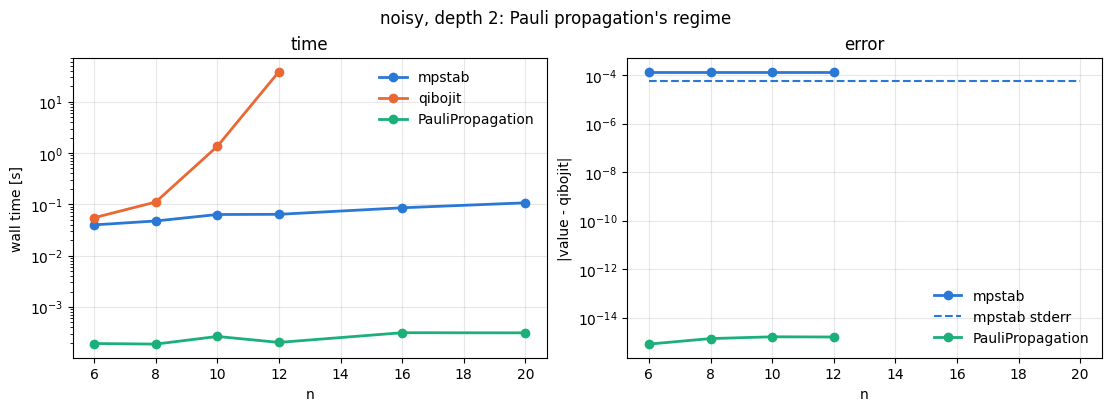

In [6]:
SIZES = [6, 8, 10, 12, 16, 20]


def noisy_case(n, depth):
    circuit = fw.kicked_ising(n, depth)
    return circuit, fw.noise_events(circuit, p=0.005, crosstalk=0.02), fw.local_z(n)


noisy = fw.sweep(((n, *noisy_case(n, 2)) for n in SIZES), label="n", qibojit=jit,
                 pauli_propagation=pp, pp_options=dict(min_abs_coeff=1e-6),
                 mpstab_options=dict(n_samples=1000, seed=0))
fw.plot(noisy, "n", "noisy, depth 2: Pauli propagation's regime");

## 3. Where mpstab wins: depth, width and many-term observables

### Depth

48 qubits, $\langle Z_{24}\rangle$, increasing depth. Pauli propagation's term
count grows exponentially with the number of magic gates in the light cone,
so to stay accurate it needs a small `min_abs_coeff`, and then its runtime
explodes. mpstab's cost follows the MPS bond dimension, which grows far more
slowly; with no cap it is exact.

/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: divide by zero encountered in matmul
  return func(*args, **kwargs)
/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: overflow encountered in matmul
  return func(*args, **kwargs)
/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: invalid value encountered in matmul
  return func(*args, **kwargs)


depth 4 done


depth 6 done


depth 8 done


depth 10 done


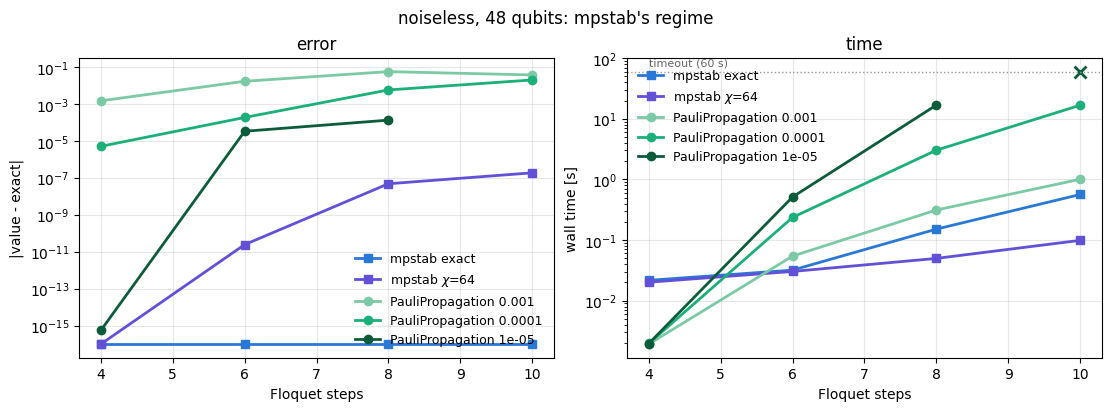

In [7]:
N, DEPTHS = 48, [4, 6, 8, 10]
observable = fw.local_z(N, (N // 2,))
rows = []
for depth in DEPTHS:
    circuit = fw.kicked_ising(N, depth)
    reference = exact_mpstab(circuit, observable)
    rows.append(dict(method="mpstab exact", depth=depth, error=0.0, time=reference["time"]))
    capped = fw.run_mpstab(circuit, observable, max_bond=64)
    rows.append(dict(method="mpstab $\\chi$=64", depth=depth,
                     error=abs(capped["value"] - reference["value"]), time=capped["time"]))
    for threshold in (1e-3, 1e-4, 1e-5):
        r = pp_isolated(circuit, observable, threshold, depth)
        rows.append(dict(method=f"PauliPropagation {threshold:g}", depth=depth,
                         error=np.nan if r is None else abs(r["value"] - reference["value"]),
                         time=np.nan if r is None else r["time"]))
    print(f"depth {depth} done")
deep = pd.DataFrame(rows)
plot_methods(deep, "depth", f"noiseless, {N} qubits: mpstab's regime", "Floquet steps");

### Width

Depth 6, growing width. qibojit doubles with every qubit; mpstab stays exact
and well under a second up to 64 qubits, while Pauli propagation at
`min_abs_coeff=1e-5` is slower and still off by $\sim 3\times10^{-5}$.

/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: divide by zero encountered in matmul
  return func(*args, **kwargs)
/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: overflow encountered in matmul
  return func(*args, **kwargs)
/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: invalid value encountered in matmul
  return func(*args, **kwargs)


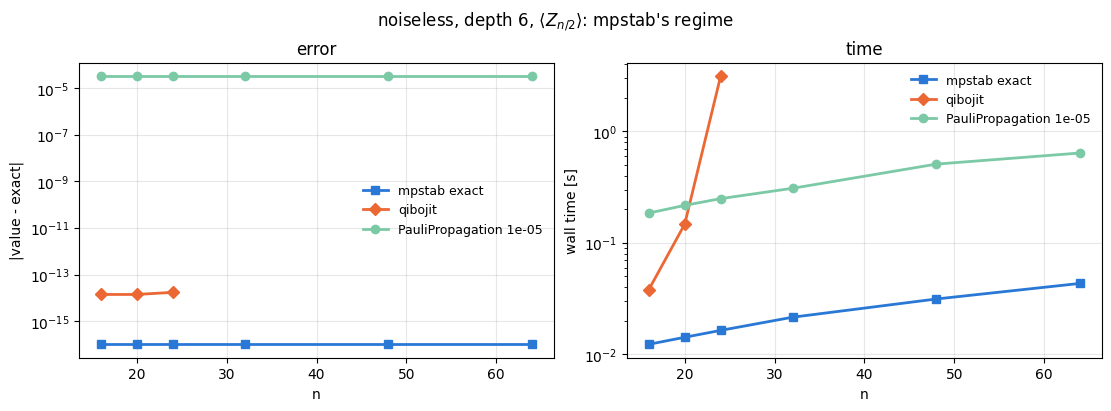

In [8]:
SIZES = [16, 20, 24, 32, 48, 64]
rows = []
for n in SIZES:
    circuit, observable = fw.kicked_ising(n, 6), fw.local_z(n, (n // 2,))
    reference = exact_mpstab(circuit, observable)
    rows.append(dict(method="mpstab exact", n=n, error=0.0, time=reference["time"]))
    if n <= 24:
        q = fw.run_qibojit(jit, circuit, [], observable)
        rows.append(dict(method="qibojit", n=n, error=abs(q["value"] - reference["value"]),
                         time=q["time"]))
    r = pp_isolated(circuit, observable, 1e-5, 6)
    rows.append(dict(method="PauliPropagation 1e-05", n=n,
                     error=np.nan if r is None else abs(r["value"] - reference["value"]),
                     time=np.nan if r is None else r["time"]))
wide = pd.DataFrame(rows)
plot_methods(wide, "n", "noiseless, depth 6, $\\langle Z_{n/2}\\rangle$: mpstab's regime");

### Observables with many terms

$\sum_i Z_i Z_{i+1}$ at depth 6: one MPS serves all $n-1$ terms, while Pauli
propagation propagates a sum whose terms branch independently.

/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: divide by zero encountered in matmul
  return func(*args, **kwargs)
/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: overflow encountered in matmul
  return func(*args, **kwargs)
/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: invalid value encountered in matmul
  return func(*args, **kwargs)


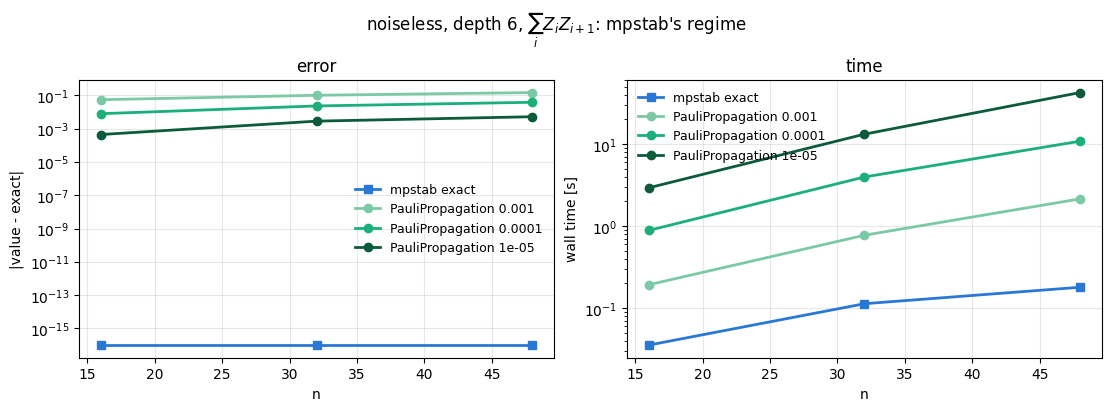

In [9]:
SIZES = [16, 32, 48]
rows = []
for n in SIZES:
    circuit, observable = fw.kicked_ising(n, 6), fw.zz_chain(n)
    reference = exact_mpstab(circuit, observable)
    rows.append(dict(method="mpstab exact", n=n, error=0.0, time=reference["time"]))
    for threshold in (1e-3, 1e-4, 1e-5):
        r = pp_isolated(circuit, observable, threshold, 6)
        rows.append(dict(method=f"PauliPropagation {threshold:g}", n=n,
                         error=np.nan if r is None else abs(r["value"] - reference["value"]),
                         time=np.nan if r is None else r["time"]))
terms = pd.DataFrame(rows)
plot_methods(terms, "n", "noiseless, depth 6, $\\sum_i Z_i Z_{i+1}$: mpstab's regime");

## 4. Accuracy against cost, side by side

How much time each method needs to reach a given error, on one case from each
regime. mpstab's knob is the bond dimension $\chi$ (noiseless) or `n_samples`
(noisy); Pauli propagation's is `min_abs_coeff`. Labels are the knob values.

/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: divide by zero encountered in matmul
  return func(*args, **kwargs)
/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: overflow encountered in matmul
  return func(*args, **kwargs)
/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: invalid value encountered in matmul
  return func(*args, **kwargs)


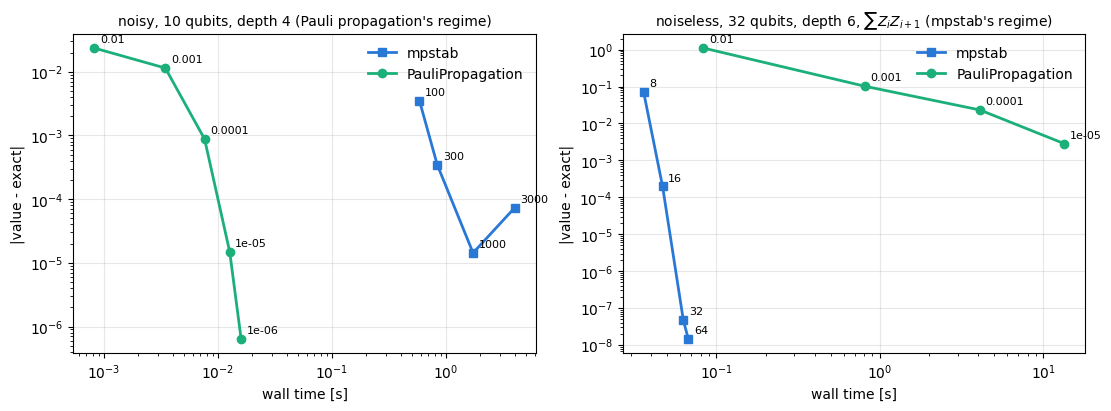

In [10]:
def tradeoff_rows(circuit, events, observable, reference, mpstab_settings, pp_thresholds):
    rows = []
    for setting in mpstab_settings:
        if events:
            r = fw.run_mpstab_noisy(circuit, events, observable, n_samples=setting, seed=0)
        else:
            r = fw.run_mpstab(circuit, observable, max_bond=setting)
        rows.append(dict(framework="mpstab", setting=setting, time=r["time"],
                         error=abs(r["value"] - reference)))
    for threshold in pp_thresholds:
        r = pp.run(circuit, events, observable, min_abs_coeff=threshold)
        rows.append(dict(framework="PauliPropagation", setting=threshold, time=r["time"],
                         error=abs(r["value"] - reference)))
    return pd.DataFrame(rows)


# Pauli propagation's regime: noisy, 10 qubits, depth 4, Z_0 Z_9
circuit, events, observable = noisy_case(10, 4)
left = tradeoff_rows(circuit, events, observable,
                     fw.run_qibojit(jit, circuit, events, observable)["value"],
                     [100, 300, 1000, 3000], [1e-2, 1e-3, 1e-4, 1e-5, 1e-6])
# mpstab's regime: noiseless, 32 qubits, depth 6, sum Z_i Z_i+1
circuit, observable = fw.kicked_ising(32, 6), fw.zz_chain(32)
right = tradeoff_rows(circuit, [], observable, exact_mpstab(circuit, observable)["value"],
                      [8, 16, 32, 64], [1e-2, 1e-3, 1e-4, 1e-5])

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
titles = ["noisy, 10 qubits, depth 4 (Pauli propagation's regime)",
          "noiseless, 32 qubits, depth 6, $\\sum Z_i Z_{i+1}$ (mpstab's regime)"]
for ax, data, title in zip(axes, (left, right), titles):
    for name, group in data.groupby("framework", sort=False):
        ax.plot(group["time"], group["error"].clip(lower=1e-16), MARKERS[name] + "-",
                color=fw.COLORS[name], linewidth=2, label=name)
        for _, row in group.iterrows():
            ax.annotate(f"{row['setting']:g}", (row["time"], max(row["error"], 1e-16)),
                        textcoords="offset points", xytext=(4, 4), fontsize=8)
    ax.set(xscale="log", yscale="log", xlabel="wall time [s]", ylabel="|value - exact|",
           title=title)
    ax.title.set_fontsize(10)
    ax.grid(alpha=0.3)
    ax.legend(frameon=False)

## 5. One build, many observables

Everything above times a single observable, rebuilding mpstab's surrogate each
time, and for one observable that is the honest cost: building the surrogate
*is* the computation, as propagation is for Pauli propagation.

With many observables of the same circuit the two diverge. mpstab evolves the
MPS once (`HSMPO(circuit)`), then each `expectation(O)` only backpropagates
`O` through the Clifford frame and sweeps the MPS. Pauli propagation works in
the Heisenberg picture, so every observable is a new propagation through the
whole circuit (Julia is compiled once, before timing).

48 qubits, depth 6, and 95 observables: every $Z_i$ and every
$Z_i Z_{i+1}$. mpstab is built with no bond cap and no SVD cutoff, so it is
exact.

In [11]:
import time

from mpstab import HSMPO
from mpstab.engines import QuimbEngine, StimEngine

N, DEPTH = 48, 6
circuit = fw.kicked_ising(N, DEPTH)
observables = [fw.local_z(N, (i,)) for i in range(N)] + [
    fw.local_z(N, (i, i + 1)) for i in range(N - 1)
]

# mpstab: one build, then one expectation per observable
t = time.perf_counter()
hsmpo = HSMPO.rotations_only(circuit)
hsmpo.progress = False
hsmpo.set_engines(stab_engine=StimEngine(), tn_engine=QuimbEngine(svd_cutoff=0.0))
build_time = time.perf_counter() - t
exact_values, mpstab_times = [], []
for observable in observables:
    t = time.perf_counter()
    exact_values.append(hsmpo.expectation(observable))
    mpstab_times.append(time.perf_counter() - t)
print(f"mpstab: build {build_time:.2f} s (bond {hsmpo.original_circuit_mps.max_bond()}), "
      f"then {np.mean(mpstab_times) * 1e3:.1f} ms per observable")

# Pauli propagation: one propagation per observable, Julia already compiled
pp.run(circuit, [], observables[N // 2], min_abs_coeff=1e-4, repeats=1)  # compile
pp_runs = {}
for threshold in (1e-4, 1e-5):
    pp_runs[threshold] = [pp.run(circuit, [], o, min_abs_coeff=threshold, repeats=1)
                          for o in observables]
    times = [r["time"] for r in pp_runs[threshold]]
    errors = [abs(r["value"] - v) for r, v in zip(pp_runs[threshold], exact_values)]
    print(f"PauliPropagation {threshold:g}: {np.mean(times) * 1e3:.0f} ms per observable, "
          f"max error {max(errors):.1e}")

mpstab: build 0.14 s (bond 64), then 1.7 ms per observable


PauliPropagation 0.0001: 287 ms per observable, max error 2.3e-03


PauliPropagation 1e-05: 771 ms per observable, max error 3.6e-04


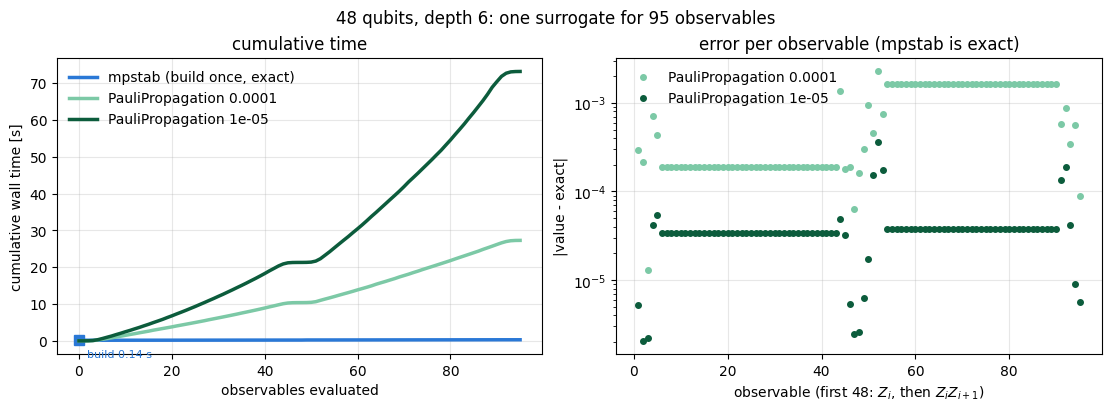

In [12]:
fig, (ax_time, ax_error) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
count = np.arange(1, len(observables) + 1)
ax_time.plot(np.concatenate([[0], count]),
             build_time + np.concatenate([[0], np.cumsum(mpstab_times)]),
             color="#2a78d6", linewidth=2.5, label="mpstab (build once, exact)")
ax_time.plot(0, build_time, "s", color="#2a78d6", markersize=7)
ax_time.annotate(f"build {build_time:.2f} s", (0, build_time), xytext=(6, -12),
                 textcoords="offset points", fontsize=8, color="#2a78d6")
for color, (threshold, runs) in zip(["#7cc9a6", "#0c5c3c"], pp_runs.items()):
    cumulative = np.cumsum([r["time"] for r in runs])
    ax_time.plot(np.concatenate([[0], count]), np.concatenate([[0], cumulative]),
                 color=color, linewidth=2.5, label=f"PauliPropagation {threshold:g}")
    errors = [abs(r["value"] - v) for r, v in zip(runs, exact_values)]
    ax_error.plot(count, np.clip(errors, 1e-16, None), "o", color=color, markersize=4,
                  label=f"PauliPropagation {threshold:g}")
ax_time.set(xlabel="observables evaluated", ylabel="cumulative wall time [s]",
            title="cumulative time")
ax_error.set(yscale="log", xlabel=f"observable (first {N}: $Z_i$, then $Z_i Z_{{i+1}}$)",
             ylabel="|value - exact|", title="error per observable (mpstab is exact)")
for ax in (ax_time, ax_error):
    ax.grid(alpha=0.3)
    ax.legend(frameon=False)
fig.suptitle(f"{N} qubits, depth {DEPTH}: one surrogate for {len(observables)} observables");

## Playground

Any circuit, events and observable: `fw.compare` runs every simulator that
fits. Build events with `fw.noise_events`, or by hand with
`mpstab.noise.PauliChannel` and `CoherentRotation`.

In [13]:
circuit = fw.hardware_efficient(12, 4, seed=1)
events = fw.noise_events(circuit, p=0.002)
observable = {"ZZ" + "I" * 10: 1.0, "I" * 5 + "XX" + "I" * 5: -0.5}
pd.DataFrame(fw.compare(circuit, events, observable, qibojit=jit, pauli_propagation=pp,
                        mpstab_options=dict(n_samples=1000, seed=0),
                        pp_options=dict(min_abs_coeff=1e-6)))

/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: divide by zero encountered in matmul
  return func(*args, **kwargs)
/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: overflow encountered in matmul
  return func(*args, **kwargs)
/Users/robbiati/Documents/PostDoc/mpstab-related/mpstab/.venv/lib/python3.11/site-packages/autoray/autoray.py:104: RuntimeWarning: invalid value encountered in matmul
  return func(*args, **kwargs)


,framework,n,gates,error,value,time,stderr,patterns,p_two_or_more,min_fidelity,terms
0,mpstab,12,96,1.0820e-04,0.4736,2.6153,0.0002,586.0,0.0162,1.0,NaN
1,qibojit,12,96,0.0000e+00,0.4737,43.6247,NaN,NaN,NaN,NaN,NaN
2,PauliPropagation,12,96,4.4409e-16,0.4737,0.0004,NaN,NaN,NaN,NaN,120.0
